# Externalities and environmental policy

External costs and Pigouvian taxation, comparative statics, and policy choice under uncertainty.

Run the notebook from top to bottom. Local section numbers are retained within each part.

1. [10c: Externalities and Pigouvian taxation](#part-10c)
2. [10d: Externality comparative statics](#part-10d)
3. [10e: Weitzman's "prices vs. quantities"](#part-10e)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from quanttoolbox.sustainable_finance.policy import weitzman_example

<a id="part-10c"></a>

## Part 1 — 10c: Externalities and Pigouvian taxation

Four related analyses: the textbook supply/demand deadweight-loss
diagram from a quantity restriction, the externality/social-marginal-
cost DWL diagram (consumer/producer surplus, external cost,
overproduction), the same model's numeric worked example at three
quantities, and the Pigouvian-tax-correction diagram showing how an
emissions tax set equal to marginal external cost at the social
optimum restores efficiency. All four sections are self-contained
(hardcoded illustrative demand/cost curves, no external data).


In [2]:
color_blue = "#1f77b4"
color_green = "#2ca02c"
color_red = "#d62728"
color_teal = "#17becf"
color_violet = "#9467bd"
color_black = "#000000"

### 1. Market equilibrium and deadweight loss from a quantity restriction

Standard supply/demand diagram: consumer and producer surplus at the
market equilibrium $(q^{\star}, p^{\star})$, then the deadweight-loss
triangle that opens up if quantity is restricted to $q' < q^{\star}$
(illustrative curve/point values).


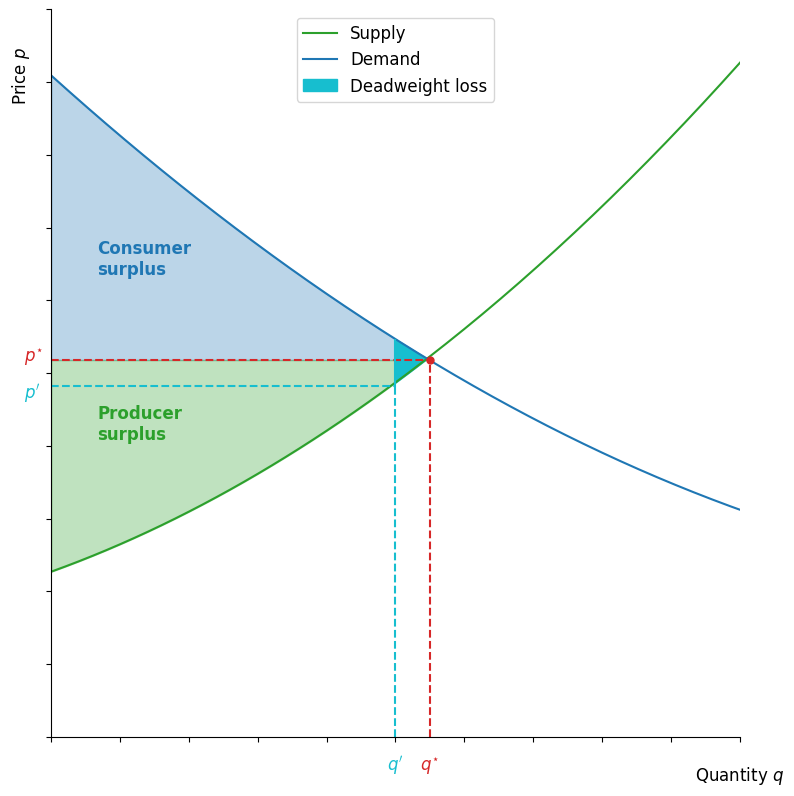

In [3]:
q = np.arange(0, 20.01, 0.1)
demand = 20 - 1.25 * q + 0.025 * q**2
supply = 5 + 0.5 * q + 0.035 * q**2
q_star, p_star = 8.25, 11.4
q_prime, p_prime, p_prime2 = 7.5, 10.6, 12.0

fig, ax = plt.subplots(figsize=(8, 8))

ax.plot(q, supply, color=color_green, lw=1.5)
ax.plot(q, demand, color=color_blue, lw=1.5)

cnd = q <= q_star
ax.fill_between(q[cnd], demand[cnd], p_star, color=color_blue, alpha=0.30)
ax.fill_between(q[cnd], supply[cnd], p_star, color=color_green, alpha=0.30)
ax.text(1.0, 14, "Consumer\nsurplus", color=color_blue, fontsize=12, fontweight="bold")
ax.text(1.0, 9, "Producer\nsurplus", color=color_green, fontsize=12, fontweight="bold")

ax.plot([0, q_star], [p_star, p_star], "--", color=color_red, lw=1.5)
ax.plot([q_star, q_star], [0, p_star], "--", color=color_red, lw=1.5)
ax.scatter([q_star], [p_star], s=25, color=color_red, zorder=5)
ax.text(q_star, -1, r"$q^{\star}$", color=color_red, fontsize=12, ha="center")
ax.text(-0.6, p_star + 0.1, r"$p^{\star}$", color=color_red, fontsize=12, va="center")

ax.plot([0, q_prime], [p_prime, p_prime], "--", color=color_teal, lw=1.5)
ax.plot([q_prime, q_prime], [0, p_prime], "--", color=color_teal, lw=1.5)
ax.plot([q_prime, q_prime], [p_prime, p_prime2], color=color_teal, lw=1.5)
ax.text(q_prime, -1, "$q'$", color=color_teal, fontsize=12, ha="center")
ax.text(-0.6, p_prime - 0.2, "$p'$", color=color_teal, fontsize=12, va="center")

cnd = (q >= q_prime) & (q <= q_star)
dwl = ax.fill_between(q[cnd], demand[cnd], supply[cnd], color=color_teal, alpha=1.0)

ax.set_xlim(0, 15)
ax.set_ylim(0, 22)
ax.set_xticks(np.linspace(0, 15, 11))
ax.set_yticks(np.linspace(0, 22, 11))
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.spines["left"].set_position("zero")
ax.spines["bottom"].set_position("zero")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# Axis titles placed as free-floating text rather than via set_xlabel/
# set_ylabel, since with both spines pinned to the origin the default
# label placement collides with the q*/p*/q'/p' annotations near the origin.
ax.text(15, -1.3, "Quantity $q$", fontsize=12, ha="center")
ax.text(-0.9, 20, "Price $p$", fontsize=12, va="center", rotation=90)
ax.legend(
    [ax.lines[0], ax.lines[1], dwl],
    ["Supply", "Demand", "Deadweight loss"],
    fontsize=12,
    loc="upper center",
)
plt.tight_layout()
plt.show()

### 2. Externality and the overproduction deadweight loss

Private marginal benefit (PMB, demand) and private marginal cost (PMC,
supply) determine the unregulated market equilibrium at $q_1=10$ (point
A/B). Adding the external marginal cost (EMC) gives the true social
marginal cost $SMC = PMC + EMC$; the social optimum is where $PMB=SMC$,
at $q_2=6$ (point C). The market overproduces by $q_1-q_2$, and the
shaded red triangle is the resulting deadweight loss.


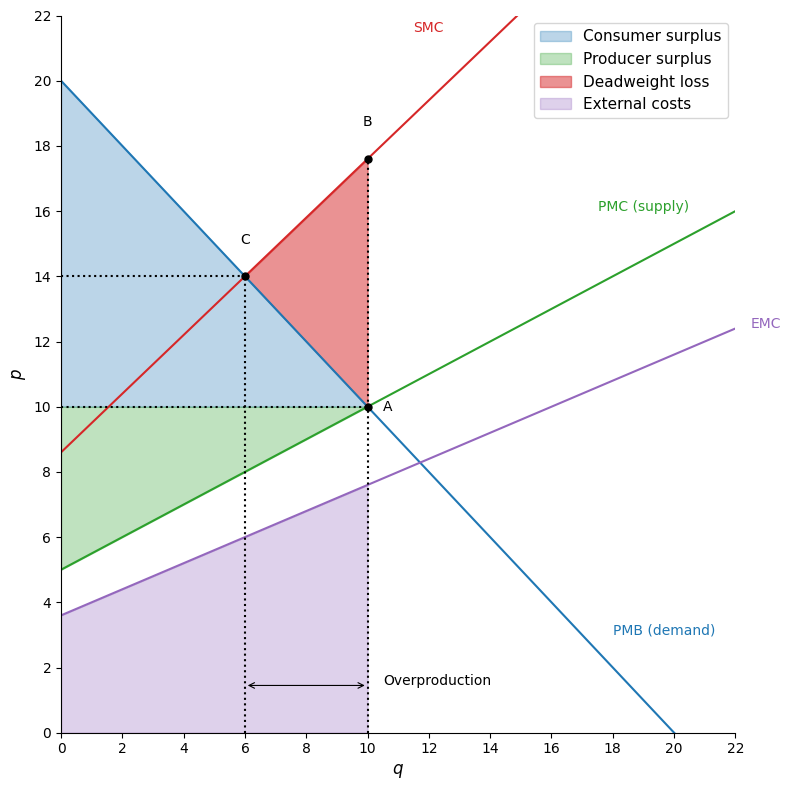

In [4]:
q2a = np.arange(0, 22.01, 0.5)
PMB = 20 - q2a
PMC = 5 + 0.5 * q2a
EMC = 3.6 + 0.4 * q2a
SMC = PMC + EMC

q1, q2 = 10, 6
PMC_q1 = 5 + 0.5 * q1
p1 = PMC_q1
SMC_q1 = 8.6 + 0.9 * q1
p1b = SMC_q1
SMC_q2 = 8.6 + 0.9 * q2
p2 = SMC_q2

fig, ax = plt.subplots(figsize=(8, 8))

ax.plot(q2a, PMB, color=color_blue, lw=1.5)
ax.plot(q2a, PMC, color=color_green, lw=1.5)
ax.plot(q2a, SMC, color=color_red, lw=1.5)
ax.plot(q2a, EMC, color=color_violet, lw=1.5)

ax.plot([0, q1], [PMC_q1, PMC_q1], ":", color=color_black, lw=1.5)
ax.plot([q1, q1], [0, SMC_q1], ":", color=color_black, lw=1.5)
ax.plot([q2, q2], [0, SMC_q2], ":", color=color_black, lw=1.5)
ax.plot([0, q2], [SMC_q2, SMC_q2], ":", color=color_black, lw=1.5)

cnd = q2a <= q1
cs = ax.fill_between(q2a[cnd], PMB[cnd], PMC_q1, color=color_blue, alpha=0.30)
ps = ax.fill_between(q2a[cnd], PMC[cnd], PMC_q1, color=color_green, alpha=0.30)
ec = ax.fill_between(q2a[cnd], EMC[cnd], 0, color=color_violet, alpha=0.30)

cnd = (q2a >= q2) & (q2a <= q1)
dwl = ax.fill_between(q2a[cnd], PMB[cnd], SMC[cnd], color=color_red, alpha=0.50)

ax.scatter([q1, q1, q2], [p1, p1b, p2], s=25, color=color_black, zorder=5)
ax.text(q1 + 0.5, p1, "A", fontsize=10, va="center")
ax.text(q1, p1b + 1.0, "B", fontsize=10, ha="center")
ax.text(q2, p2 + 1.0, "C", fontsize=10, ha="center")
ax.text(q1 + 0.5, 1.45, "Overproduction", fontsize=10)
ax.text(22.5, 12.4, "EMC", color=color_violet, fontsize=10)
ax.text(20.5, 16, "PMC (supply)", color=color_green, fontsize=10, ha="right")
ax.text(18, 3, "PMB (demand)", color=color_blue, fontsize=10)
ax.text(11.5, 21.5, "SMC", color=color_red, fontsize=10)
ax.annotate("", xy=(q1, 1.45), xytext=(q2, 1.45), arrowprops=dict(arrowstyle="<->", lw=0.8))

ax.set_xlim(0, 22)
ax.set_ylim(0, 22)
ax.set_xticks(np.arange(0, 23, 2))
ax.set_yticks(np.arange(0, 23, 2))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("$q$", fontsize=12)
ax.set_ylabel("$p$", fontsize=12)
ax.legend(
    [cs, ps, dwl, ec],
    ["Consumer surplus", "Producer surplus", "Deadweight loss", "External costs"],
    fontsize=11,
    loc="upper right",
)
plt.tight_layout()
plt.show()

### 3. Numeric worked example

The same PMB/PMC/EMC model evaluated at three quantities ($q=10, 9, 6$)
using the total (integrated) benefit/cost/external-cost functions
$PB(q)$, $PC(q)$, $EC(q)$ (whose derivatives are $PMB$, $PMC$, $EMC$
above), shown as a printed diagnostic table. Net social benefit
$PB - PC - EC$ is maximized at $q=6$, confirming the social optimum
found graphically in Section 2.


In [5]:
PB = lambda q: 5 + 20 * q - 0.5 * q**2
PC = lambda q: 1 + 5 * q + 0.25 * q**2
EC = lambda q: 3.6 * q + 0.2 * q**2
PMB_f = lambda q: 20 - q
PMC_f = lambda q: 5 + 0.5 * q
EMC_f = lambda q: 3.6 + 0.4 * q

rows = []
for qv in [10, 9, 6]:
    rows.append(
        {
            "q": qv,
            "PB(q)": PB(qv),
            "PC(q)": PC(qv),
            "EC(q)": EC(qv),
            "Net = PB-PC-EC": PB(qv) - PC(qv) - EC(qv),
            "PMB(q)": PMB_f(qv),
            "PMC(q)": PMC_f(qv),
            "EMC(q)": EMC_f(qv),
        }
    )
pd.DataFrame(rows).set_index("q").round(2)

,PB(q),PC(q),EC(q),Net = PB-PC-EC,PMB(q),PMC(q),EMC(q)
q,,,,,,,
10,155.0,76.00,56.0,23.00,10,10.0,7.6
9,144.5,66.25,48.6,29.65,11,9.5,7.2
6,107.0,40.00,28.8,38.20,14,8.0,6.0


### 4. The Pigouvian tax correction

Setting an emissions tax equal to the marginal external cost evaluated
at the social optimum, $\mathrm{Tax}=EMC(q_2^{\star})$, shifts the
private supply curve from $PMC$ up to $PMC' = PMC+\mathrm{Tax}$. The
new (taxed) market equilibrium, where $PMB=PMC'$, lands exactly at the
socially optimal quantity $q_2=6$ found in Section 2 — the tax fully
internalizes the externality.


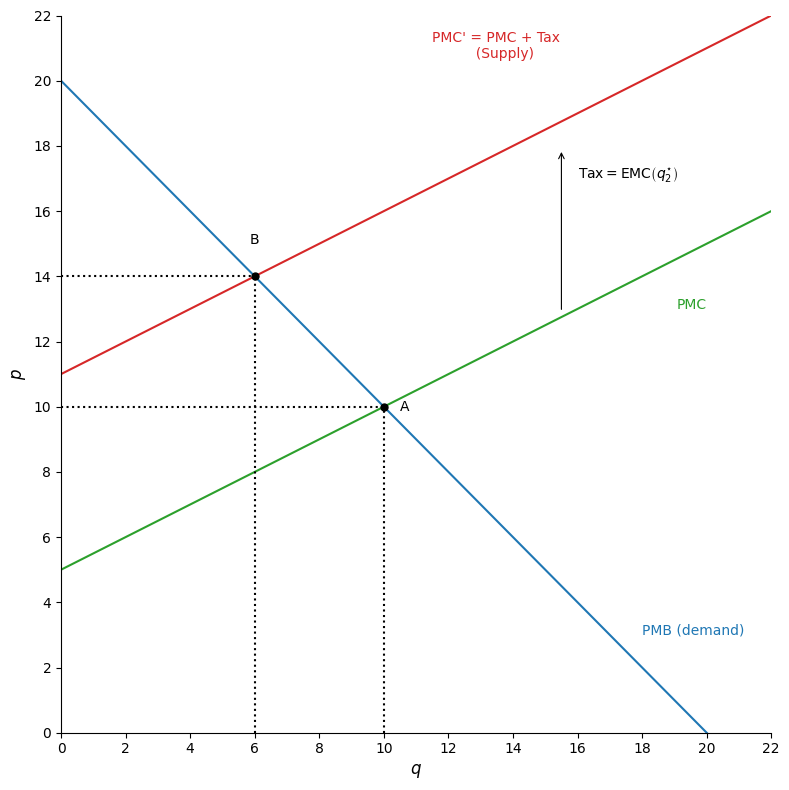

In [6]:
q3 = np.arange(0, 22.01, 0.5)
PMB3 = 20 - q3
PMC3 = 5 + 0.5 * q3

q1, q2 = 10, 6
PMC_q1 = 5 + 0.5 * q1
p1 = PMC_q1
SMC_q2 = 8.6 + 0.9 * q2
p2 = SMC_q2
EMC_q2 = 3.6 + 0.4 * q2
tax = EMC_q2
SMC_tax = PMC3 + tax

fig, ax = plt.subplots(figsize=(8, 8))

ax.plot(q3, PMB3, color=color_blue, lw=1.5)
ax.plot(q3, PMC3, color=color_green, lw=1.5)
ax.plot(q3, SMC_tax, color=color_red, lw=1.5)

ax.plot([0, q1], [PMC_q1, PMC_q1], ":", color=color_black, lw=1.5)
ax.plot([q1, q1], [0, PMC_q1], ":", color=color_black, lw=1.5)
ax.plot([q2, q2], [0, SMC_q2], ":", color=color_black, lw=1.5)
ax.plot([0, q2], [SMC_q2, SMC_q2], ":", color=color_black, lw=1.5)

ax.scatter([q1, q2], [p1, p2], s=25, color=color_black, zorder=5)
ax.text(q1 + 0.5, p1, "A", fontsize=10, va="center")
ax.text(q2, p2 + 1.0, "B", fontsize=10, ha="center")
ax.text(20, 13.0, "PMC", color=color_green, fontsize=10, ha="right")
ax.text(18, 3, "PMB (demand)", color=color_blue, fontsize=10)
ax.text(11.5, 20.7, "PMC' = PMC + Tax\n          (Supply)", color=color_red, fontsize=10)
ax.text(
    16.0,
    17.0,
    r"$\mathrm{Tax} = \mathrm{EMC}\left(q^{\star}_2\right)$",
    color=color_black,
    fontsize=10,
)
ax.annotate("", xy=(15.5, 17.9), xytext=(15.5, 12.9), arrowprops=dict(arrowstyle="->", lw=0.8))

ax.set_xlim(0, 22)
ax.set_ylim(0, 22)
ax.set_xticks(np.arange(0, 23, 2))
ax.set_yticks(np.arange(0, 23, 2))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("$q$", fontsize=12)
ax.set_ylabel("$p$", fontsize=12)
plt.tight_layout()
plt.show()

<a id="part-10d"></a>

## Part 2 — 10d: Externality comparative statics

Five comparative-statics variants of the same linear social-marginal-
benefit (SMB) / social-marginal-cost (SMC) diagram, illustrating what
happens to the market equilibrium — and to two different deadweight-
loss measures — when either curve shifts:

- **Sections 1, 4**: SMC shifts up (SMB fixed), at two different sets
  of curve slopes/intercepts.
- **Section 2**: SMB shifts down (SMC fixed).
- **Section 3**: SMB shifts up (SMC fixed).
- **Section 5**: SMB shifts down (SMC fixed), same slopes as Section 4.

All five share an identical underlying construction, so they are built
here via one shared parametrized helper function rather than five
near-duplicate code blocks. For each pair of curves (original vs.
shifted), five points are located: $A$ (original equilibrium), $B$ (new
equilibrium), $C$ (the *new* curve evaluated at the *old* equilibrium
quantity $q_1^{\star}$), and $E$/$D$ (the new curve, resp. the fixed
curve, evaluated at the quantity where the new curve reaches the *old*
equilibrium price $p_1^{\star}$). Two deadweight-loss triangles are then
shaded: $\mathrm{DWL}(q_1^{\star})$ (triangle $A$-$B$-$C$, the loss from
holding *quantity* fixed at the old optimum despite the shift) and
$\mathrm{DWL}(p_2^{\star})$ (triangle $B$-$E$-$D$, the loss from holding
*price* fixed at the old optimum instead). All self-contained
(hardcoded linear curves, no external data).


In [7]:
def smb(q, alpha, beta):
    return alpha - beta * q


def smc(q, alpha, beta):
    return alpha + beta * q


def intersect(alpha_B, beta_B, alpha_C, beta_C):
    q = (alpha_B - alpha_C) / (beta_B + beta_C)
    p = (alpha_B * beta_C + alpha_C * beta_B) / (beta_B + beta_C)
    return q, p


def dwl_shift_diagram(
    shift,
    params1,
    params2,
    point_offsets,
    point_labels,
    curve_labels,
    legend_loc,
    use_latex_points=False,
):
    """Shared construction for the five comparative-statics diagrams below.

    shift: 'cost' (SMC shifts, SMB fixed) or 'benefit' (SMB shifts, SMC fixed).
    params1: (alpha_B, beta_B, alpha_C1, beta_C1) — the fixed curve plus the
      *original* version of the shifting curve.
    params2: (alpha_C2, beta_C2) if shift == 'cost', or (alpha_B2, beta_B2)
      if shift == 'benefit' — the *shifted* version of the shifting curve.
    """
    q = np.arange(0, 22.01, 0.5)
    alpha_B, beta_B, alpha_C1, beta_C1 = params1

    if shift == "cost":
        alpha_C2, beta_C2 = params2
        curve_fixed_y = smb(q, alpha_B, beta_B)
        curve_v1_y = smc(q, alpha_C1, beta_C1)
        curve_v2_y = smc(q, alpha_C2, beta_C2)
        qA, pA = intersect(alpha_B, beta_B, alpha_C1, beta_C1)
        qB, pB = intersect(alpha_B, beta_B, alpha_C2, beta_C2)
        pE = pA
        qE = (pE - alpha_C2) / beta_C2
        qD, pD = qE, smb(qE, alpha_B, beta_B)
        qC, pC = qA, smc(qA, alpha_C2, beta_C2)
    else:
        alpha_B2, beta_B2 = params2
        curve_fixed_y = smc(q, alpha_C1, beta_C1)
        curve_v1_y = smb(q, alpha_B, beta_B)
        curve_v2_y = smb(q, alpha_B2, beta_B2)
        qA, pA = intersect(alpha_B, beta_B, alpha_C1, beta_C1)
        qB, pB = intersect(alpha_B2, beta_B2, alpha_C1, beta_C1)
        pE = pA
        qE = (alpha_B2 - pE) / beta_B2
        qD, pD = qE, smc(qE, alpha_C1, beta_C1)
        qC, pC = qA, smb(qA, alpha_B2, beta_B2)

    fig, ax = plt.subplots(figsize=(8, 8))
    # Color convention: blue is always the SMB-side curve at its original
    # level (the fixed SMB when SMC is shifting, or SMB1 when SMB itself is
    # shifting), green is always the SMC-side curve at its original level,
    # and red is always the shifted (v2) curve, whichever side it's on.
    if shift == "cost":
        blue_y, green_y = curve_fixed_y, curve_v1_y
    else:
        blue_y, green_y = curve_v1_y, curve_fixed_y
    ax.plot(q, blue_y, color=color_blue, lw=1.5)
    ax.plot(q, green_y, color=color_green, lw=1.5)
    ax.plot(q, curve_v2_y, color=color_red, lw=1.5)

    # dotted guide lines to A and B
    ax.plot([0, qA], [pA, pA], ":", color=color_black, lw=1.5)
    ax.plot([qA, qA], [0, pA], ":", color=color_black, lw=1.5)
    ax.plot([0, qB], [pB, pB], ":", color=color_black, lw=1.5)
    ax.plot([qB, qB], [0, pB], ":", color=color_black, lw=1.5)
    # vertical guide at the shared E/D quantity, and at C's quantity
    ax.plot([qE, qE], [0, max(pE, pD)], ":", color=color_black, lw=1.5)
    ax.plot([qC, qC], [0, pC], ":", color=color_black, lw=1.5)

    pts = [(qA, pA), (qB, pB), (qE, pE), (qD, pD), (qC, pC)]
    ax.scatter([p[0] for p in pts], [p[1] for p in pts], s=25, color=color_black, zorder=5)
    labels = ["$A$", "$B$", "$E$", "$D$", "$C$"] if use_latex_points else ["A", "B", "E", "D", "C"]
    for (px, py), lab, (dx, dy) in zip(pts, labels, point_offsets):
        ax.text(px + dx, py + dy, lab, fontsize=10, ha="center", va="center")

    for text, x, y, color, ha in curve_labels:
        ax.text(x, y, text, color=color, fontsize=10, ha=ha)

    patch1 = ax.fill([qA, qB, qC], [pA, pB, pC], color=color_red, alpha=0.30, edgecolor="none")[0]
    patch2 = ax.fill([qB, qE, qD], [pB, pE, pD], color=color_violet, alpha=0.30, edgecolor="none")[
        0
    ]

    ax.set_xlim(0, 22)
    ax.set_ylim(0, 22)
    ax.set_xticks(np.arange(0, 23, 2))
    ax.set_yticks(np.arange(0, 23, 2))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel("$q$", fontsize=12)
    ax.set_ylabel("$p$", fontsize=12)
    ax.legend(
        [patch1, patch2],
        [r"$\mathrm{DWL}(q_1^{\star})$", r"$\mathrm{DWL}(p_2^{\star})$"],
        fontsize=12,
        loc=legend_loc,
    )
    plt.tight_layout()
    plt.show()

### 1. SMC shifts up, moderate slope

$SMB=20-q$ (fixed); $SMC$ moves from $8+0.25q$ to $10+0.25q$.


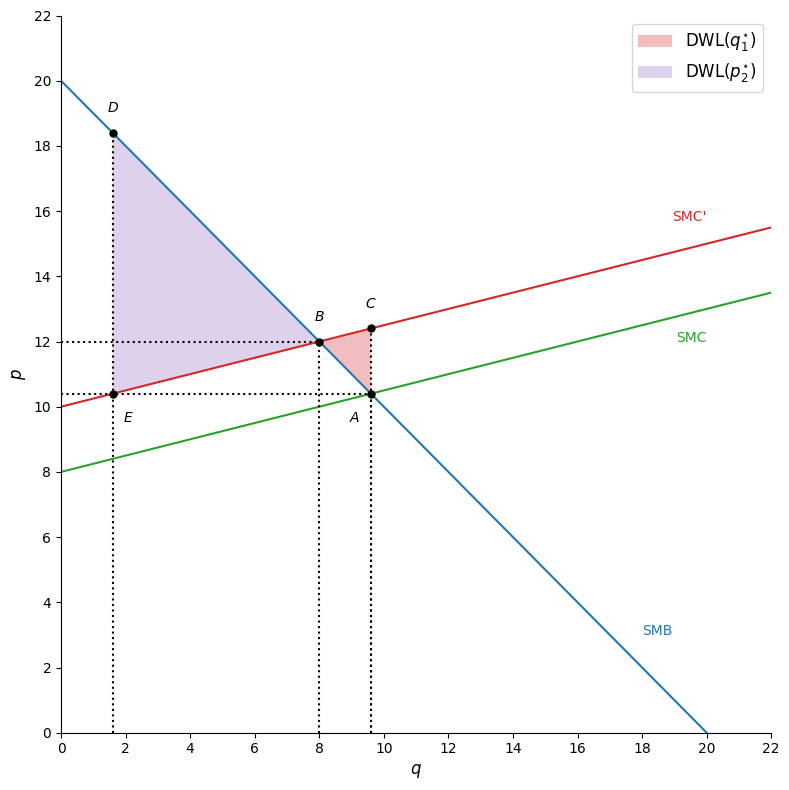

In [8]:
dwl_shift_diagram(
    shift="cost",
    params1=(20, 1, 8, 0.25),
    params2=(10, 0.25),
    point_offsets=[(-0.50, -0.75), (0.00, 0.75), (0.50, -0.75), (0.00, 0.75), (0.00, 0.75)],
    point_labels=["A", "B", "E", "D", "C"],
    curve_labels=[
        ("SMB", 18, 3, color_blue, "left"),
        ("SMC", 20, 12.0, color_green, "right"),
        ("SMC'", 20, 15.7, color_red, "right"),
    ],
    legend_loc="upper right",
    use_latex_points=True,
)

### 2. SMB shifts down

$SMC=8+0.25q$ (fixed); $SMB$ moves from $20-q$ to $15-q$.


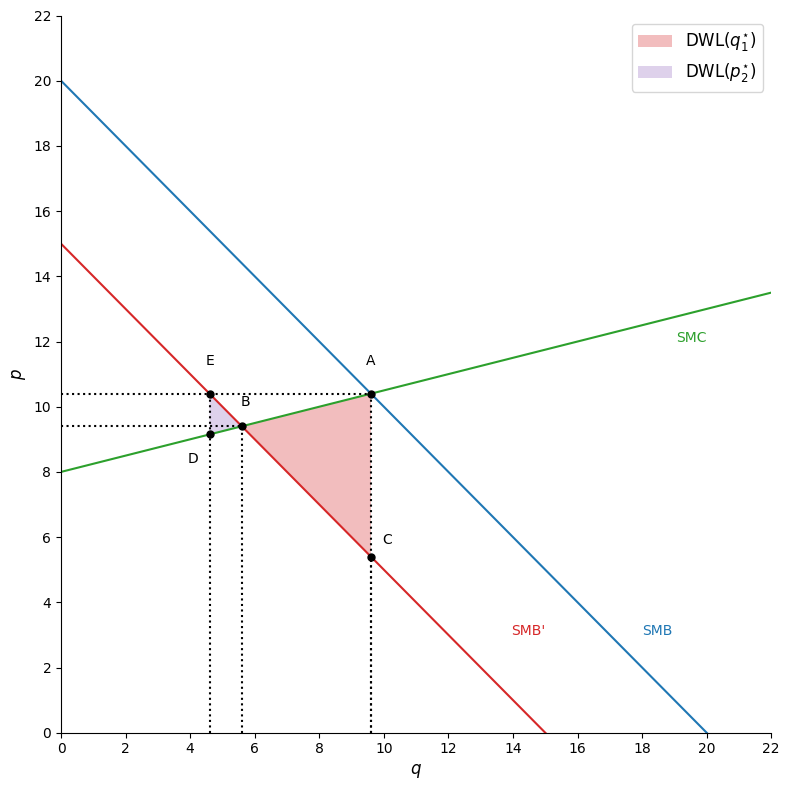

In [9]:
dwl_shift_diagram(
    shift="benefit",
    params1=(20, 1, 8, 0.25),
    params2=(15, 1),
    point_offsets=[(0.00, 1.00), (0.10, 0.75), (0.0, 1.0), (-0.5, -0.75), (0.5, 0.5)],
    point_labels=["A", "B", "E", "D", "C"],
    curve_labels=[
        ("SMB", 18, 3, color_blue, "left"),
        ("SMC", 20, 12.0, color_green, "right"),
        ("SMB'", 15, 3, color_red, "right"),
    ],
    legend_loc="upper right",
    use_latex_points=False,
)

### 3. SMB shifts up

$SMC=8+0.25q$ (fixed); $SMB$ moves from $20-q$ to $25-q$.


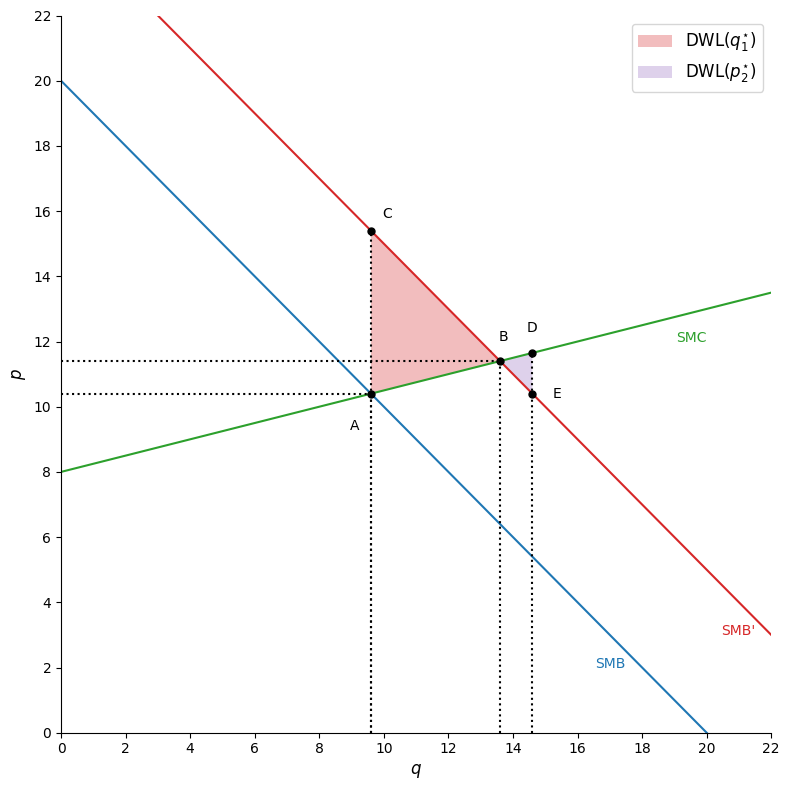

In [10]:
dwl_shift_diagram(
    shift="benefit",
    params1=(20, 1, 8, 0.25),
    params2=(25, 1),
    point_offsets=[(-0.50, -1.00), (0.10, 0.75), (0.75, 0.00), (0.00, 0.75), (0.50, 0.50)],
    point_labels=["A", "B", "E", "D", "C"],
    curve_labels=[
        ("SMB", 17.5, 2, color_blue, "right"),
        ("SMC", 20, 12.0, color_green, "right"),
        ("SMB'", 21.5, 3, color_red, "right"),
    ],
    legend_loc="upper right",
    use_latex_points=False,
)

### 4. SMC shifts up, steep slope

$SMB=18-0.5q$ (fixed); $SMC$ moves from $1+q$ to $7+q$ — a steeper pair
of curves than Section 1, showing the same construction generalizes.


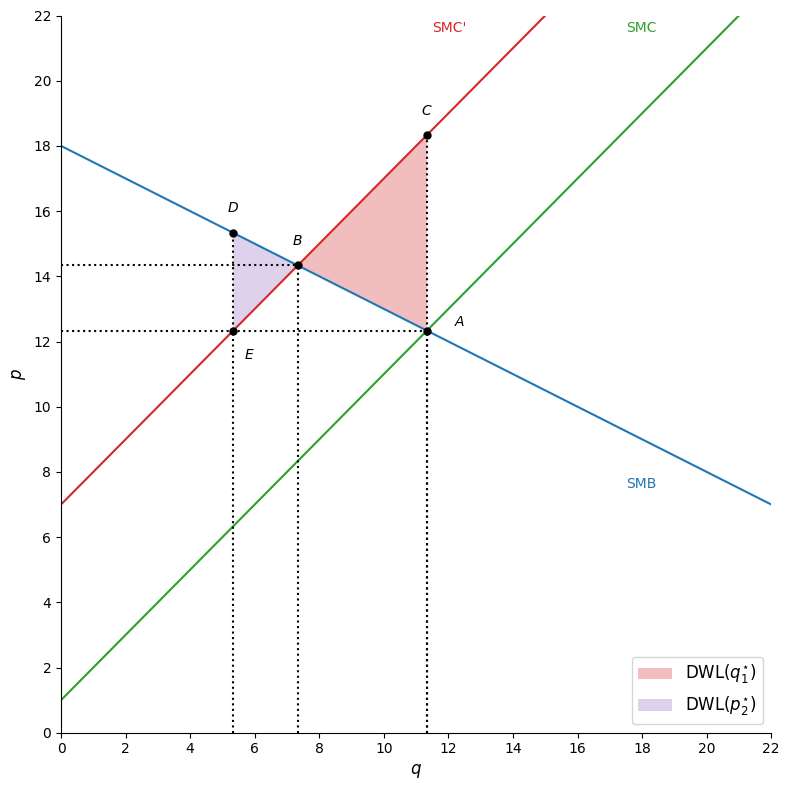

In [11]:
dwl_shift_diagram(
    shift="cost",
    params1=(18, 0.5, 1, 1.0),
    params2=(7, 1.0),
    point_offsets=[(1.00, 0.25), (0.00, 0.75), (0.50, -0.75), (0.00, 0.75), (0.00, 0.75)],
    point_labels=["A", "B", "E", "D", "C"],
    curve_labels=[
        ("SMB", 17.5, 7.5, color_blue, "left"),
        ("SMC", 17.5, 21.5, color_green, "left"),
        ("SMC'", 11.5, 21.5, color_red, "left"),
    ],
    legend_loc="lower right",
    use_latex_points=True,
)

### 5. SMB shifts down, steep slope

$SMC=1+q$ (fixed); $SMB$ moves from $18-0.5q$ to $15-0.5q$ — the mirror
comparative-static of Section 4.


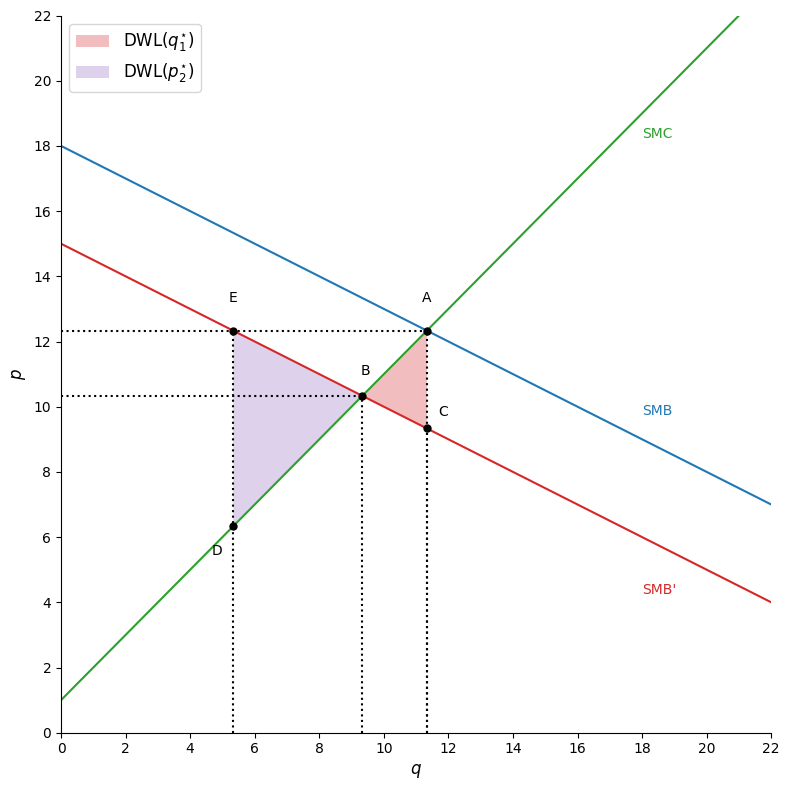

In [12]:
dwl_shift_diagram(
    shift="benefit",
    params1=(18, 0.5, 1, 1.0),
    params2=(15, 0.5),
    point_offsets=[(0.00, 1.00), (0.10, 0.75), (0.0, 1.0), (-0.5, -0.75), (0.5, 0.5)],
    point_labels=["A", "B", "E", "D", "C"],
    curve_labels=[
        ("SMB", 18, 9.75, color_blue, "left"),
        ("SMC", 18, 18.25, color_green, "left"),
        ("SMB'", 18, 4.25, color_red, "left"),
    ],
    legend_loc="upper left",
    use_latex_points=False,
)

<a id="part-10e"></a>

## Part 3 — 10e: Weitzman's "prices vs. quantities"

Explores Weitzman's (1974) classic result on choosing a **quantity
instrument** (an emissions cap, fixed regardless of how costly
abatement turns out to be) versus a **price instrument** (an emissions
tax, fixed regardless of the resulting quantity) when the regulator
sets policy *before* observing the true realization of marginal
abatement cost, across four parameterizations.

One case worth flagging: Section 2's three-state setup has a
near-duplicate that just condenses the same inputs into a re-run
without the intermediate numerical-integration check, so it isn't
rebuilt separately here.

**The model.** Social marginal benefit is linear and known:
$SMB(q)=\alpha_B-\beta_B q$. Social marginal cost is linear but
uncertain: $SMC(q,\epsilon)=\alpha_C+\beta_C q+\epsilon$, where
$\epsilon$ is a random shock (a discrete distribution $\{\epsilon_i,
p_i\}$ here) not yet known when the instrument is chosen. The regulator
sets policy using only the *expected* cost curve (i.e. $\mathrm{E}
[\epsilon]$), then the shock $\epsilon_i$ is realized:

- **Quantity instrument**: cap quantity at $q_1^{\star}$, the quantity
  that would be optimal under the *expected* cost curve. This quantity
  never adjusts to the realized shock.
- **Price instrument**: set a tax equal to $p^{\star}$, the price that
  would clear the market under the *expected* cost curve. Firms then
  choose $q_2^{\star}(\epsilon_i)$ so that $SMC(q,\epsilon_i)=p^{\star}$
  — this quantity *does* adjust to the realized shock, since the firm
  observes its own true marginal cost even though the regulator didn't.

Realized welfare is $W(q,\epsilon)=\int_0^q\left[SMB(x)-SMC(x,\epsilon)
\right]dx$. Weitzman's result: $\mathrm{E}[W(q_2^{\star})]-\mathrm{E}
[W(q_1^{\star})] = \dfrac{\sigma_\epsilon^2}{2\beta_C}\left(1-\dfrac
{\beta_B}{\beta_C}\right)$ — the price instrument wins exactly when the
marginal-cost curve is steeper than the marginal-benefit curve
($\beta_C>\beta_B$), and the quantity instrument wins when it's the
other way around. All sections are self-contained (hardcoded
illustrative parameters, no external data).


In [13]:
def display_weitzman_example(
    alpha_B, beta_B, alpha_C, beta_C, epsilon_i, p_i, check_numerical=False
):
    result = weitzman_example(alpha_B, beta_B, alpha_C, beta_C, epsilon_i, p_i)
    epsilon_i = result.epsilon_i
    p_i = result.p_i

    def dW(q, epsilon):
        return (alpha_B - beta_B * q) - (alpha_C + beta_C * q + epsilon)

    def W_analytical(q, epsilon):
        return ((alpha_B - alpha_C - epsilon) - 0.5 * q * (beta_B + beta_C)) * q

    if check_numerical:
        W_numerical = np.array(
            [[quad(dW, 0, qv, args=(eps,))[0] for qv in [0, 1, 2, 3, 4]] for eps in epsilon_i]
        )
        W_check = np.array([[W_analytical(qv, eps) for qv in [0, 1, 2, 3, 4]] for eps in epsilon_i])
        max_err = np.max(np.abs(W_numerical - W_check))
        print(f"Max |analytical - numerical (scipy.integrate.quad)| welfare error: {max_err:.2e}")

    table = pd.DataFrame(
        {
            "epsilon_i": epsilon_i,
            "p_i": p_i,
            "q*_i (ex-post optimum)": result.q_star_i,
            "q1*_i (quantity instr.)": result.q1_ast_i,
            "q2*_i (price instr.)": result.q2_ast_i,
            "W(q1*_i)": result.w_q1_ast_i,
            "W(q2*_i)": result.w_q2_ast_i,
        }
    )
    display(table.round(3))
    print(f"mean(epsilon) = {result.mean_epsilon:.3f}, sigma(epsilon) = {result.sigma_epsilon:.3f}")
    print(f"q* = {result.q_ast:.3f}, p* = {result.p_ast:.3f}")
    print(f"E[W(q1*)] (quantity instrument) = {result.e_w_q1_ast:.4f}")
    print(f"E[W(q2*)] (price instrument)    = {result.e_w_q2_ast:.4f}")
    print(
        f"Delta(W) = E[W(q2*)] - E[W(q1*)] = {result.delta_w:.4f}  "
        f"(closed form: {result.delta_w_analytical:.4f})"
    )
    winner = "price" if result.delta_w > 0 else "quantity"
    print(
        f"-> beta_C={beta_C} {'>' if beta_C > beta_B else '<'} beta_B={beta_B}, "
        f"so the {winner} instrument dominates in expectation."
    )
    return result

### 1. Two-state uncertainty

A simple symmetric two-state cost shock: $\epsilon\in\{+30,-30\}$ with
equal probability. $\beta_C=8 > \beta_B=2$ (the marginal-cost curve is
much steeper than the marginal-benefit curve), so Weitzman's result
predicts the price instrument should dominate. The welfare integral is
also cross-checked analytically against `scipy.integrate.quad`.


In [14]:
_ = display_weitzman_example(
    alpha_B=100,
    beta_B=2,
    alpha_C=20,
    beta_C=8,
    epsilon_i=[30, -30],
    p_i=[0.50, 0.50],
    check_numerical=True,
)

Max |analytical - numerical (scipy.integrate.quad)| welfare error: 5.68e-14


,epsilon_i,p_i,q*_i (ex-post optimum),q1*_i (quantity instr.),q2*_i (price instr.),W(q1*_i),W(q2*_i)
0,30.0,0.5,5.0,8.0,4.25,80.0,122.188
1,-30.0,0.5,11.0,8.0,11.75,560.0,602.188


mean(epsilon) = 0.000, sigma(epsilon) = 30.000
q* = 8.000, p* = 84.000
E[W(q1*)] (quantity instrument) = 320.0000
E[W(q2*)] (price instrument)    = 362.1875
Delta(W) = E[W(q2*)] - E[W(q1*)] = 42.1875  (closed form: 42.1875)
-> beta_C=8 > beta_B=2, so the price instrument dominates in expectation.


### 2. Three-state uncertainty

A right-skewed three-state cost shock. Same qualitative conclusion
($\beta_C=8 > \beta_B=2$): the price instrument wins in expectation,
though by a different margin since the shock distribution has changed.
(A condensed rerun of this exact case without the numerical check is
skipped here as a near-duplicate.)


In [15]:
_ = display_weitzman_example(
    alpha_B=100, beta_B=2, alpha_C=20, beta_C=8, epsilon_i=[10, 30, 50], p_i=[0.40, 0.35, 0.25]
)

,epsilon_i,p_i,q*_i (ex-post optimum),q1*_i (quantity instr.),q2*_i (price instr.),W(q1*_i),W(q2*_i)
0,10.0,0.40,7.0,5.3,7.425,230.55,244.097
1,30.0,0.35,5.0,5.3,4.925,124.55,124.972
2,50.0,0.25,3.0,5.3,2.425,18.55,43.347


mean(epsilon) = 27.000, sigma(epsilon) = 15.843
q* = 5.300, p* = 89.400
E[W(q1*)] (quantity instrument) = 140.4500
E[W(q2*)] (price instrument)    = 152.2156
Delta(W) = E[W(q2*)] - E[W(q1*)] = 11.7656  (closed form: 11.7656)
-> beta_C=8 > beta_B=2, so the price instrument dominates in expectation.


### 3. Closer slopes — a smaller margin

Now the two curves' slopes are much closer ($\beta_C=5$ vs.
$\beta_B=4$), so the price instrument's advantage should shrink
relative to Sections 1-2. This case is also the $\beta_C=5$ point of
the slope sweep built in Section 4.


In [16]:
_ = display_weitzman_example(
    alpha_B=100, beta_B=4, alpha_C=20, beta_C=5, epsilon_i=[10, 25, 50], p_i=[0.40, 0.50, 0.10]
)

,epsilon_i,p_i,q*_i (ex-post optimum),q1*_i (quantity instr.),q2*_i (price instr.),W(q1*_i),W(q2*_i)
0,10.0,0.4,7.778,6.5,8.8,264.875,267.52
1,25.0,0.5,6.111,6.5,5.8,167.375,167.62
2,50.0,0.1,3.333,6.5,0.8,4.875,21.12


mean(epsilon) = 21.500, sigma(epsilon) = 11.843
q* = 6.500, p* = 74.000
E[W(q1*)] (quantity instrument) = 190.1250
E[W(q2*)] (price instrument)    = 192.9300
Delta(W) = E[W(q2*)] - E[W(q1*)] = 2.8050  (closed form: 2.8050)
-> beta_C=5 > beta_B=4, so the price instrument dominates in expectation.


### 4. Sweeping the cost-curve slope

Repeats Section 3's setup for a range of $\beta_C$ values from 1 to 10
(holding $\beta_B=4$ fixed), plotting $\mathrm{E}[W(q_1^{\star})]$ and
$\mathrm{E}[W(q_2^{\star})]$ against $\beta_C$. The two curves cross
exactly at $\beta_C=\beta_B=4$ (dotted vertical line): for
$\beta_C<\beta_B$ the quantity instrument dominates (shaded red,
$\Delta\le 0$); for $\beta_C>\beta_B$ the price instrument dominates
(shaded teal, $\Delta\ge 0$) — this is Weitzman's rule visualized
directly.


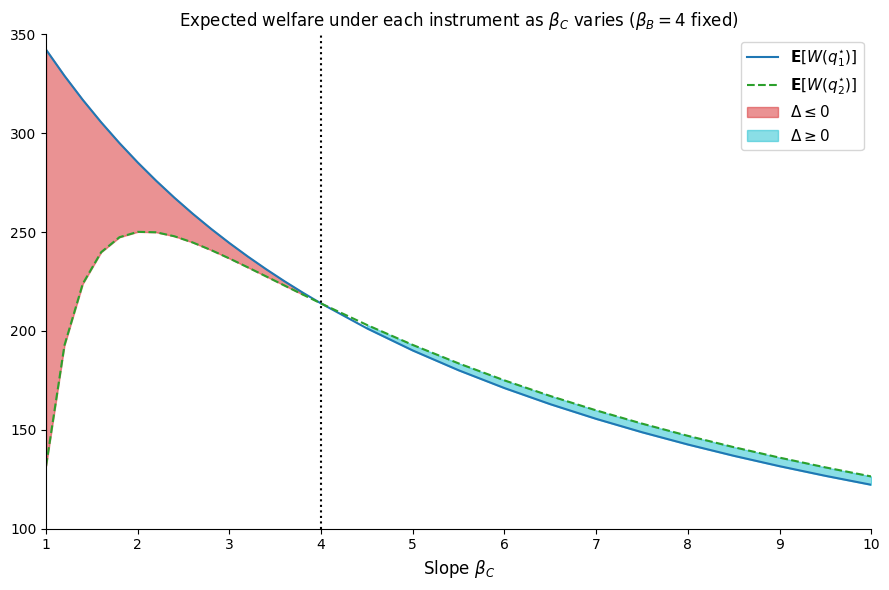

In [17]:
import matplotlib.pyplot as plt

color_blue = "#1f77b4"
color_green = "#2ca02c"
color_red = "#d62728"
color_teal = "#17becf"
color_black = "#000000"

alpha_B, beta_B, alpha_C = 100, 4, 20
epsilon_i = np.array([10, 25, 50], dtype=float)
p_i = np.array([0.40, 0.50, 0.10])
mean_epsilon = np.sum(p_i * epsilon_i)
sigma_epsilon = np.sqrt(np.sum(p_i * (epsilon_i - mean_epsilon) ** 2))

beta_C_vector = np.concatenate([np.arange(1, 4, 0.2), np.arange(4, 10.5, 0.5)])
E_W_q1 = np.zeros_like(beta_C_vector)
E_W_q2 = np.zeros_like(beta_C_vector)
Delta_W = np.zeros_like(beta_C_vector)

for i, beta_C in enumerate(beta_C_vector):
    E_W_q1[i] = 0.5 * (alpha_B - alpha_C - mean_epsilon) ** 2 / (beta_B + beta_C)
    E_W_q2[i] = (
        (alpha_B - alpha_C - mean_epsilon) ** 2 * beta_C**2
        + sigma_epsilon**2 * (beta_C**2 - beta_B**2)
    ) / (2 * (beta_B + beta_C) * beta_C**2)
    Delta_W[i] = sigma_epsilon**2 * (1 - beta_B / beta_C) / (2 * beta_C)

fig, ax = plt.subplots(figsize=(9, 6))
(line1,) = ax.plot(beta_C_vector, E_W_q1, "-", color=color_blue, lw=1.5)
(line2,) = ax.plot(beta_C_vector, E_W_q2, "--", color=color_green, lw=1.5)
ax.plot([beta_B, beta_B], [100, 350], ":", color=color_black, lw=1.5)

cnd = Delta_W < 0
patch1 = ax.fill_between(beta_C_vector[cnd], E_W_q1[cnd], E_W_q2[cnd], color=color_red, alpha=0.50)
cnd = Delta_W > 0
patch2 = ax.fill_between(beta_C_vector[cnd], E_W_q1[cnd], E_W_q2[cnd], color=color_teal, alpha=0.50)

ax.set_xlim(1, 10)
ax.set_ylim(100, 350)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel(r"Slope $\beta_C$", fontsize=12)
ax.legend(
    [line1, line2, patch1, patch2],
    [
        r"$\mathbf{E}[W(q_1^{\star})]$",
        r"$\mathbf{E}[W(q_2^{\star})]$",
        r"$\Delta \leq 0$",
        r"$\Delta \geq 0$",
    ],
    fontsize=11,
    loc="upper right",
)
ax.set_title(r"Expected welfare under each instrument as $\beta_C$ varies ($\beta_B=4$ fixed)")
plt.tight_layout()
plt.show()